# Population GHSL 2020 → Grille existante

In [4]:
import numpy as np
import pandas as pd
import rasterio
from pyproj import Transformer

In [5]:
# Charger la grille existante
grid = pd.read_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid.csv")
print(f"Points dans la grille : {len(grid):,}")
grid.head()

Points dans la grille : 89,198


,latitude,longitude,landcover
0,36.987823,-7.963676,210
1,36.994129,-8.952213,110
2,36.996850,-7.974890,210
3,37.003139,-8.952309,210
4,37.003216,-8.941076,210


In [ ]:

tif_path = r"C:\Users\admin\Desktop\Fire-forest-predection\Data\GHSL_Population\ghsl_pop_portugal_2020_100m.tif"

with rasterio.open(tif_path) as src:
    raster_crs = src.crs
    nodata_value = src.nodata
    
    # Transformer les coords de la grille (WGS84) vers le CRS du raster si nécessaire
    if str(raster_crs) != "EPSG:4326":
        transformer = Transformer.from_crs("EPSG:4326", raster_crs, always_xy=True)
        coords = [transformer.transform(lon, lat) for lon, lat in zip(grid["longitude"], grid["latitude"])]
    else:
        coords = list(zip(grid["longitude"], grid["latitude"]))
    
    # Échantillonnage
    sampled = np.array([v[0] for v in src.sample(coords)])

print(f"Échantillonnage terminé : {len(sampled):,} valeurs")
print(f"CRS du raster : {raster_crs}")
print(f"Nodata : {nodata_value}")

Échantillonnage terminé : 89,198 valeurs
CRS du raster : EPSG:4326
Nodata : None


In [7]:
# Ajouter la colonne population à la grille
grid["population"] = sampled

# Remplacer nodata par 0
if nodata_value is not None:
    grid.loc[grid["population"] == nodata_value, "population"] = 0.0

# Les valeurs négatives (artefacts) → 0
grid.loc[grid["population"] < 0, "population"] = 0.0

# Stats
print(f"Population min  : {grid['population'].min():.2f}")
print(f"Population max  : {grid['population'].max():.2f}")
print(f"Population moy  : {grid['population'].mean():.2f}")
print(f"Points pop > 0  : {(grid['population'] > 0).sum():,} / {len(grid):,}")
print(f"NaN             : {grid['population'].isna().sum()}")

Population min  : 0.00
Population max  : 534.05
Population moy  : 7.41
Points pop > 0  : 13,287 / 89,198
NaN             : 75909


In [12]:
# Remplacer les NaN par 0 (pas de population détectée = 0 habitants)
grid["population"] = grid["population"].fillna(0.0)

print(f"NaN restants : {grid['population'].isna().sum()}")
print(f"Points à 0   : {(grid['population'] == 0).sum():,}")
print(f"Points > 0   : {(grid['population'] > 0).sum():,}")

NaN restants : 0
Points à 0   : 75,911
Points > 0   : 13,287


In [13]:
# Sauvegarder
output_path = "C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid_with_population.csv"
grid.to_csv(output_path, index=False)
print(f"✅ Sauvegardé : {output_path}")
print(f"   Colonnes : {list(grid.columns)}")
grid.head(10)

✅ Sauvegardé : C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid_with_population.csv
   Colonnes : ['latitude', 'longitude', 'landcover', 'population']


,latitude,longitude,landcover,population
0,36.987823,-7.963676,210,0.0
1,36.994129,-8.952213,110,0.0
2,36.996850,-7.974890,210,0.0
3,37.003139,-8.952309,210,0.0
4,37.003216,-8.941076,210,0.0
5,37.003292,-8.929842,210,0.0
6,37.005875,-7.986107,210,0.0
7,37.005860,-7.974872,210,0.0
8,37.005845,-7.963636,210,0.0
9,37.005792,-7.929930,200,0.0


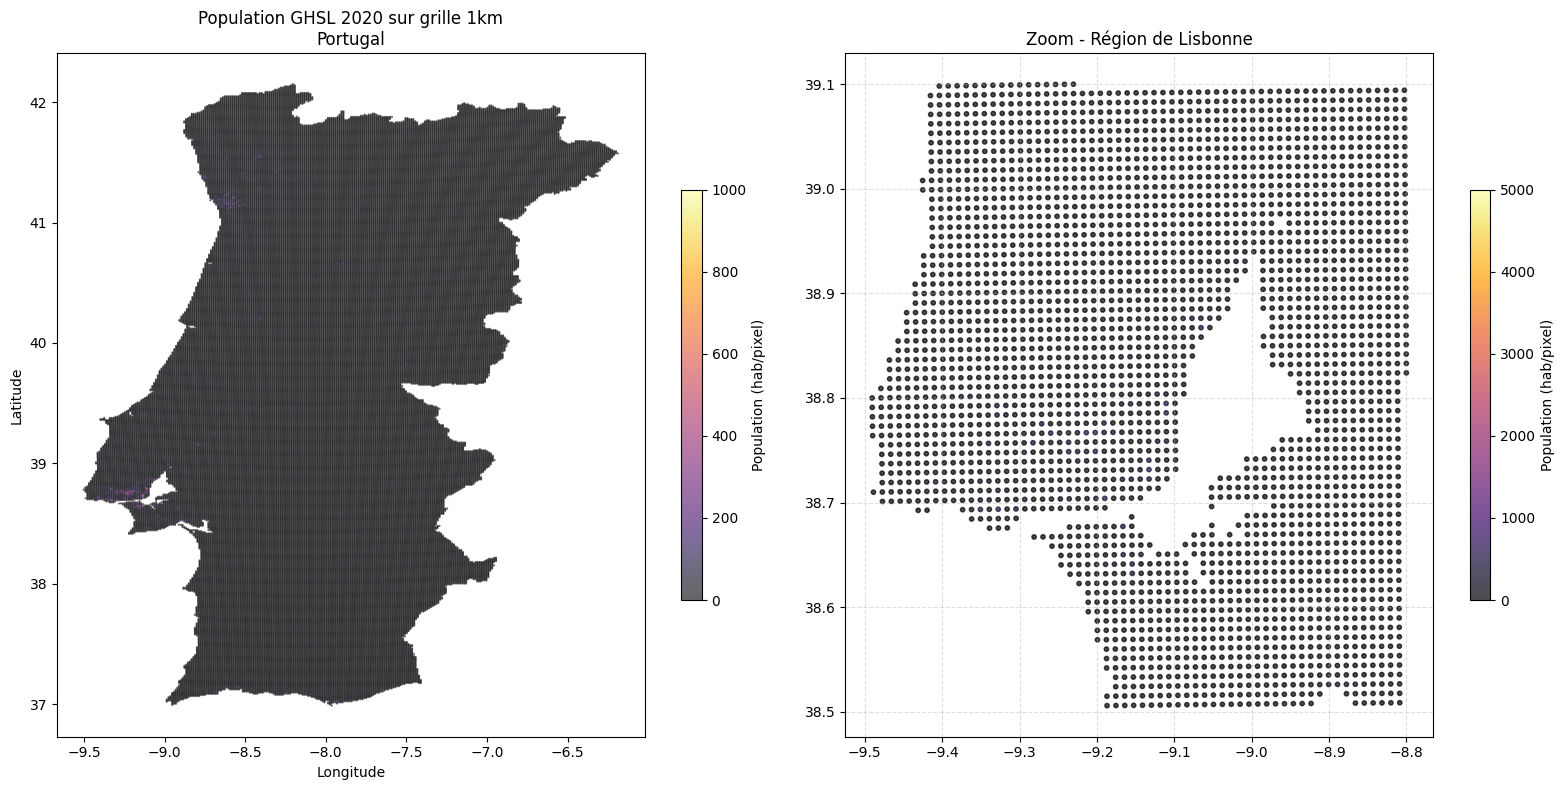

In [14]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Vue d'ensemble
sc = ax1.scatter(
    grid["longitude"], grid["latitude"],
    c=grid["population"], cmap="inferno",
    s=0.3, alpha=0.6, vmin=0, vmax=1000
)
plt.colorbar(sc, ax=ax1, label="Population (hab/pixel)", shrink=0.6)
ax1.set_title("Population GHSL 2020 sur grille 1km\nPortugal")
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")

# Zoom Lisbonne
mask = (
    (grid["longitude"] > -9.5) & (grid["longitude"] < -8.8) &
    (grid["latitude"] > 38.5) & (grid["latitude"] < 39.1)
)
sc2 = ax2.scatter(
    grid.loc[mask, "longitude"], grid.loc[mask, "latitude"],
    c=grid.loc[mask, "population"], cmap="inferno",
    s=10, alpha=0.7, vmin=0, vmax=5000
)
plt.colorbar(sc2, ax=ax2, label="Population (hab/pixel)", shrink=0.6)
ax2.set_title("Zoom - Région de Lisbonne")
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()